# Loan Prediciton with Logistic Regression

## Data

**Problem Statement**

Loan Prediction with Logistic Regression




**Data**

Dataset contains various demographic and financial features that could be used to build a classification model for predicting loan approval or denial.


**Link Dataset :**

https://www.kaggle.com/datasets/sujithmandala/simple-loan-classification-dataset

## Import Library

In [2]:
#importing Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

## Load Data

In [4]:
df = pd.read_csv('/content/sample_data/mall_customers_data.csv')
df.head()

,CustomerID,Gender,Age,Annual_Income,Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Data Understanding

In [5]:
df.shape

(200, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual_Income           200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [7]:
df.describe()

,CustomerID,Age,Annual_Income,Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.00000
mean,100.500000,39.115000,59.815000,50.61500
std,57.879185,13.821612,27.738564,25.63283
min,1.000000,18.000000,6.000000,1.00000
25%,50.750000,29.000000,40.000000,35.00000
50%,100.500000,36.000000,60.500000,50.00000
75%,150.250000,49.000000,77.250000,73.00000
max,200.000000,70.000000,170.000000,98.00000


In [8]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual_Income,0
Spending Score (1-100),0


## Data Cleansing

In [ ]:
# Check missing value

df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual_Income,0
Spending Score (1-100),0


In [9]:
# Check null value
df.isnull().sum()*100/df.shape[0]

,0
CustomerID,0.0
Gender,0.0
Age,0.0
Annual_Income,0.0
Spending Score (1-100),0.0


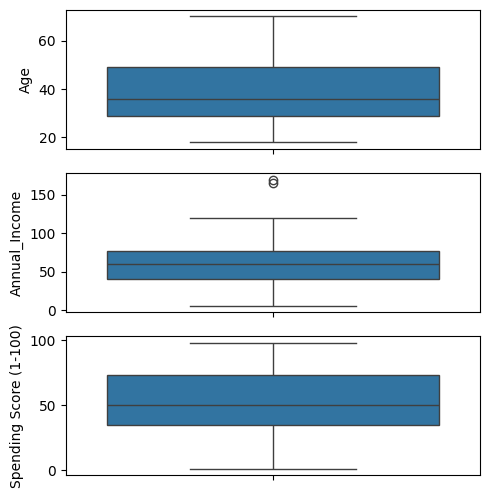

In [13]:
# Outlier Analysis
fig, axs = plt.subplots(3, figsize = (5,5))
plt1 = sns.boxplot(df['Age'], ax = axs[0])
plt2 = sns.boxplot(df['Annual_Income'], ax = axs[1])
plt3 = sns.boxplot(df['Spending Score (1-100)'], ax = axs[2])
plt.tight_layout()

## EDA

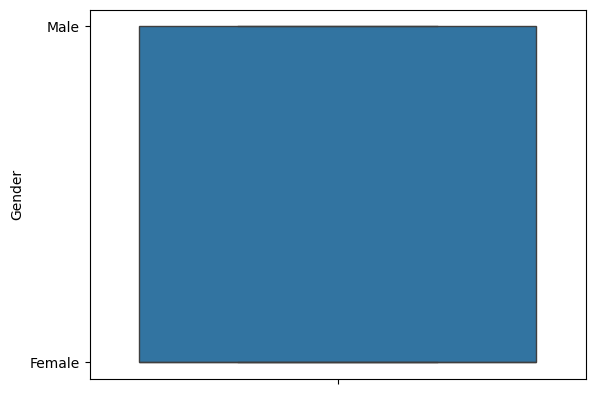

In [14]:
# Univariate Analysis

sns.boxplot(df['Gender'])
plt.show()

In [ ]:
# Memisahkan fitur dan target
X = df[['Gender', 'Age', 'Annual_Income']]
y = df['Spending Score (1-100)'] > 50  # Membuat target biner

# Membagi data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

[[14  9]
 [ 3 14]]
              precision    recall  f1-score   support

       False       0.82      0.61      0.70        23
        True       0.61      0.82      0.70        17

    accuracy                           0.70        40
   macro avg       0.72      0.72      0.70        40
weighted avg       0.73      0.70      0.70        40



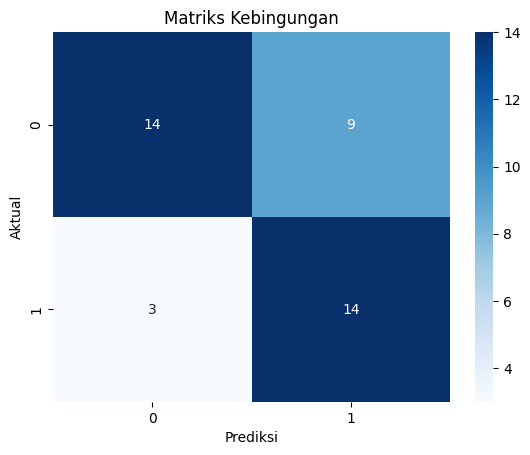

In [ ]:
y_pred = model.predict(X_test)

# Menghitung matriks kebingungan
conf_matrix = confusion_matrix(y_test, y_pred)
print(conf_matrix)

# Menampilkan laporan klasifikasi
class_report = classification_report(y_test, y_pred)
print(class_report)

# Visualisasi matriks kebingungan
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Matriks Kebingungan')
plt.show()

In [ ]:
# Menghitung variabel numerik dalam DataFrame
numerical = [var for var in df.columns if df[var].dtype != 'O']

# Menampilkan jumlah dan nama variabel numerik
print('There are {} numerical variables\n'.format(len(numerical)))
print('The numerical variables are:', numerical)

There are 5 numerical variables

The numerical variables are: ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending Score (1-100)']


In [ ]:
df[numerical].head()

,CustomerID,Gender,Age,Annual_Income,Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


In [ ]:
df[numerical].isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual_Income,0
Spending Score (1-100),0


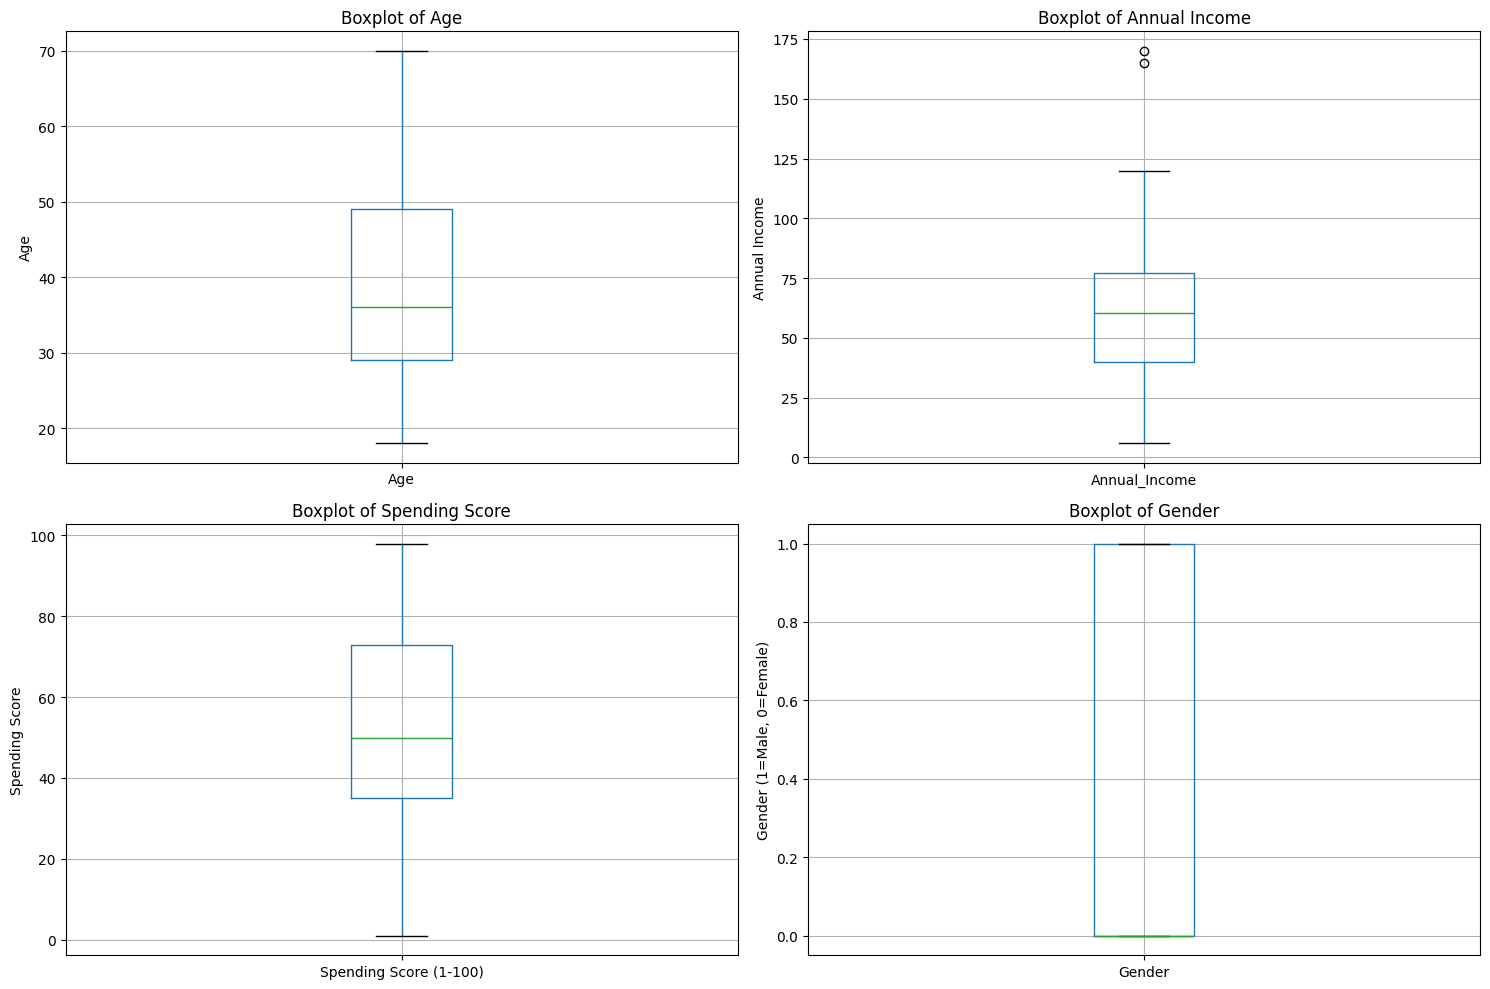

In [ ]:
# Membuat figure dengan ukuran yang ditentukan
plt.figure(figsize=(15, 10))

# Subplot 1: Boxplot untuk Age
plt.subplot(2, 2, 1)
fig = df.boxplot(column='Age')
fig.set_title('Boxplot of Age')
fig.set_ylabel('Age')

# Subplot 2: Boxplot untuk Annual Income
plt.subplot(2, 2, 2)
fig = df.boxplot(column='Annual_Income')
fig.set_title('Boxplot of Annual Income')
fig.set_ylabel('Annual Income')

# Subplot 3: Boxplot untuk Spending Score
plt.subplot(2, 2, 3)
fig = df.boxplot(column='Spending Score (1-100)')
fig.set_title('Boxplot of Spending Score')
fig.set_ylabel('Spending Score')

# Subplot 4: Boxplot untuk Gender
plt.subplot(2, 2, 4)
fig = df.boxplot(column='Gender')
fig.set_title('Boxplot of Gender')
fig.set_ylabel('Gender (1=Male, 0=Female)')

# Menampilkan plot
plt.tight_layout()
plt.show()

In [ ]:
label_encoder = LabelEncoder()


df['Annual_Income'] = label_encoder.fit_transform(df['education_level'])


df.drop(columns=['education_level'], inplace=True)

print(df.head())

   age  gender  occupation marital_status  income  credit_score loan_status  \
0   32     0.0    Engineer        Married   85000           720    Approved   
1   45     1.0     Teacher         Single   62000           680    Approved   
2   28     0.0     Student         Single   25000           590      Denied   
3   51     1.0     Manager        Married  105000           780    Approved   
4   36     0.0  Accountant        Married   75000           710    Approved   

   education_level_encoded  
0                        1  
1                        4  
2                        3  
3                        1  
4                        1  


In [ ]:
label_encoder = LabelEncoder()

df['occupation_encoded'] = label_encoder.fit_transform(df['occupation'])

df.drop(columns=['occupation'], inplace=True)

print(df.head())

   age  gender marital_status  income  credit_score loan_status  \
0   32     0.0        Married   85000           720    Approved   
1   45     1.0         Single   62000           680    Approved   
2   28     0.0         Single   25000           590      Denied   
3   51     1.0        Married  105000           780    Approved   
4   36     0.0        Married   75000           710    Approved   

   education_level_encoded  occupation_encoded  
0                        1                  12  
1                        4                  35  
2                        3                  33  
3                        1                  16  
4                        1                   0  


In [ ]:
label_encoder = LabelEncoder()

df['marital_status_encoded'] = label_encoder.fit_transform(df['marital_status'])


df.drop(columns=['marital_status'], inplace=True)

print(df.head())

   age  gender  income  credit_score loan_status  education_level_encoded  \
0   32     0.0   85000           720    Approved                        1   
1   45     1.0   62000           680    Approved                        4   
2   28     0.0   25000           590      Denied                        3   
3   51     1.0  105000           780    Approved                        1   
4   36     0.0   75000           710    Approved                        1   

   occupation_encoded  marital_status_encoded  
0                  12                       0  
1                  35                       1  
2                  33                       1  
3                  16                       0  
4                   0                       0  


In [ ]:
label_encoder = LabelEncoder()

df['loan_status_encoded'] = label_encoder.fit_transform(df['loan_status'])


df.drop(columns=['loan_status'], inplace=True)


print(df.head())

   age  gender  income  credit_score  education_level_encoded  \
0   32     0.0   85000           720                        1   
1   45     1.0   62000           680                        4   
2   28     0.0   25000           590                        3   
3   51     1.0  105000           780                        1   
4   36     0.0   75000           710                        1   

   occupation_encoded  marital_status_encoded  loan_status_encoded  
0                  12                       0                    0  
1                  35                       1                    0  
2                  33                       1                    1  
3                  16                       0                    0  
4                   0                       0                    0  


In [ ]:
print("Distribution of categorical variables:")
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"Column: {col}")
    print(df[col].value_counts())
    print()

Distribution of categorical variables:


In [ ]:
print("Distribution of numerical variables:")
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
for col in num_cols:
    print(f"Column: {col}")
    print(df[col].describe())
    print()

Distribution of numerical variables:
Column: age
count    61.000000
mean     37.081967
std       8.424755
min      24.000000
25%      30.000000
50%      36.000000
75%      43.000000
max      55.000000
Name: age, dtype: float64

Column: gender
count    61.000000
mean      0.491803
std       0.504082
min       0.000000
25%       0.000000
50%       0.000000
75%       1.000000
max       1.000000
Name: gender, dtype: float64

Column: income
count        61.000000
mean      78983.606557
std       33772.025802
min       25000.000000
25%       52000.000000
50%       78000.000000
75%       98000.000000
max      180000.000000
Name: income, dtype: float64

Column: credit_score
count     61.000000
mean     709.836066
std       72.674888
min      560.000000
25%      650.000000
50%      720.000000
75%      770.000000
max      830.000000
Name: credit_score, dtype: float64

Column: education_level_encoded
count    61.000000
mean      2.032787
std       1.378008
min       0.000000
25%       1.000000
50

In [ ]:
# find numerical variables

numerical = [var for var in df.columns if df[var].dtype!='O']

print('There are {} numerical variables\n'.format(len(numerical)))

print('The numerical variables are :', numerical)

There are 8 numerical variables

The numerical variables are : ['age', 'gender', 'income', 'credit_score', 'education_level_encoded', 'occupation_encoded', 'marital_status_encoded', 'loan_status_encoded']


In [ ]:
df[numerical].head()

,age,gender,income,credit_score,education_level_encoded,occupation_encoded,marital_status_encoded,loan_status_encoded
0,32,0.0,85000,720,1,12,0,0
1,45,1.0,62000,680,4,35,1,0
2,28,0.0,25000,590,3,33,1,1
3,51,1.0,105000,780,1,16,0,0
4,36,0.0,75000,710,1,0,0,0


In [ ]:
df[numerical].isnull().sum()

,0
age,0
gender,0
income,0
credit_score,0
education_level_encoded,0
occupation_encoded,0
marital_status_encoded,0
loan_status_encoded,0


Text(0, 0.5, 'education_level_encoded')

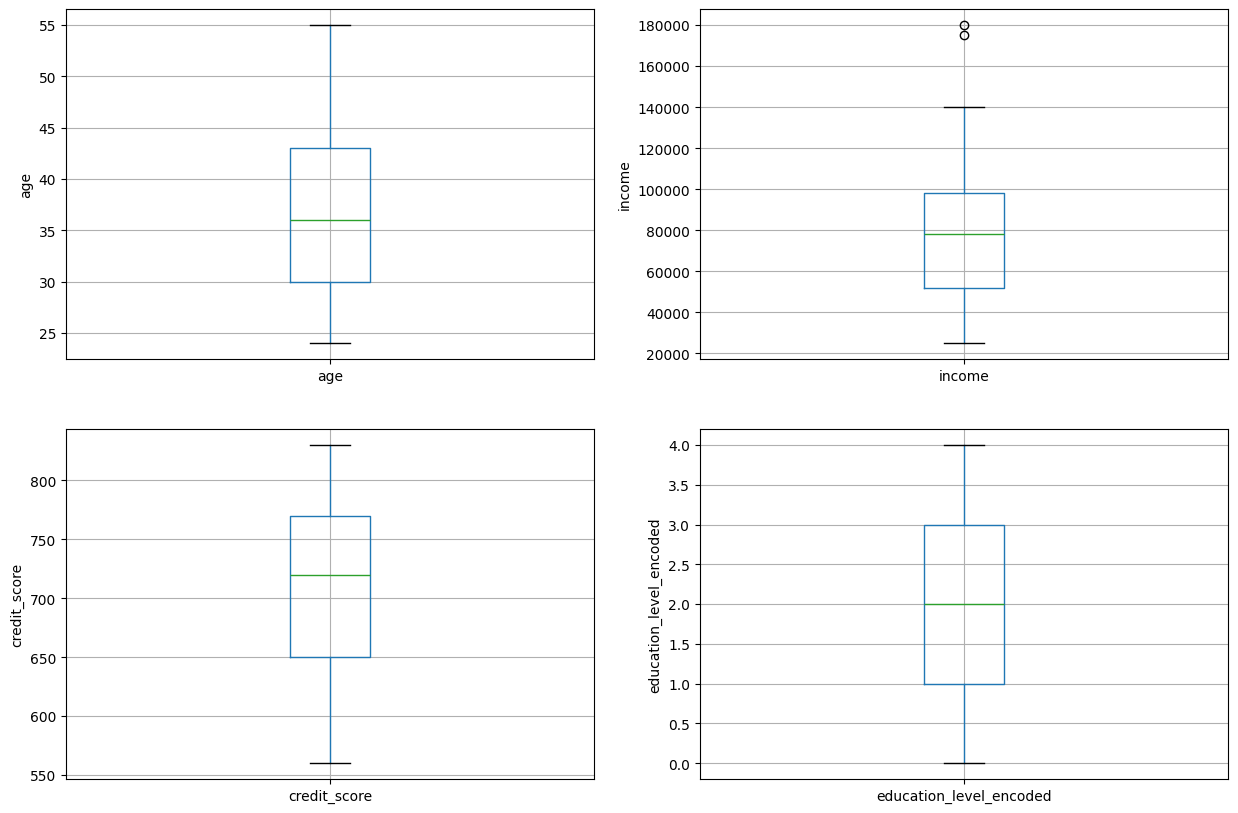

In [ ]:
plt.figure(figsize=(15,10))


plt.subplot(2, 2, 1)
fig = df.boxplot(column='age')
fig.set_title('')
fig.set_ylabel('age')


plt.subplot(2, 2, 2)
fig = df.boxplot(column='income')
fig.set_title('')
fig.set_ylabel('income')


plt.subplot(2, 2, 3)
fig = df.boxplot(column='credit_score')
fig.set_title('')
fig.set_ylabel('credit_score')

plt.subplot(2, 2, 4)
fig = df.boxplot(column='education_level_encoded')
fig.set_title('')
fig.set_ylabel('education_level_encoded')

Text(0, 0.5, 'loan_status_encoded')

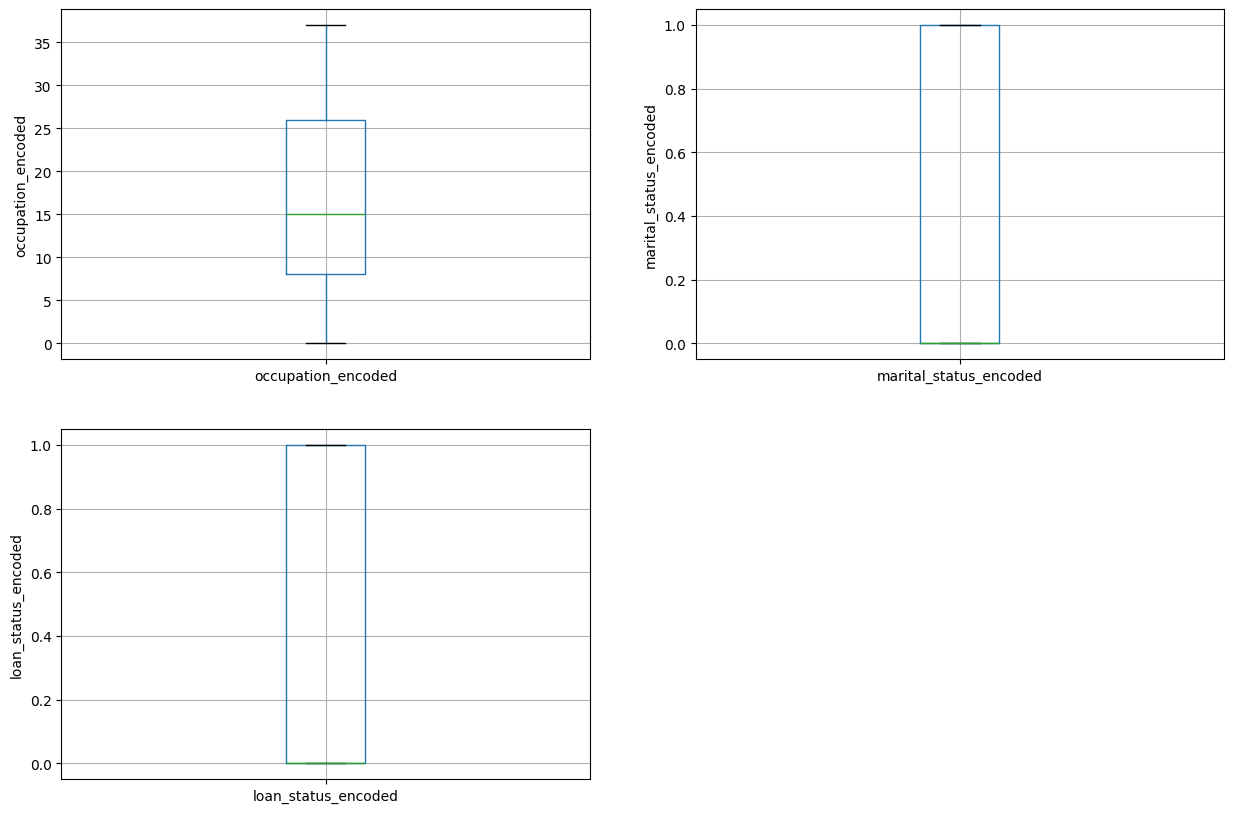

In [ ]:
plt.figure(figsize=(15,10))
plt.subplot(2, 2, 1)
fig = df.boxplot(column='occupation_encoded')
fig.set_title('')
fig.set_ylabel('occupation_encoded')

plt.subplot(2, 2, 2)
fig = df.boxplot(column='marital_status_encoded')
fig.set_title('')
fig.set_ylabel('marital_status_encoded')

plt.subplot(2, 2, 3)
fig = df.boxplot(column='loan_status_encoded')
fig.set_title('')
fig.set_ylabel('loan_status_encoded')

Text(0, 0.5, 'credit_score')

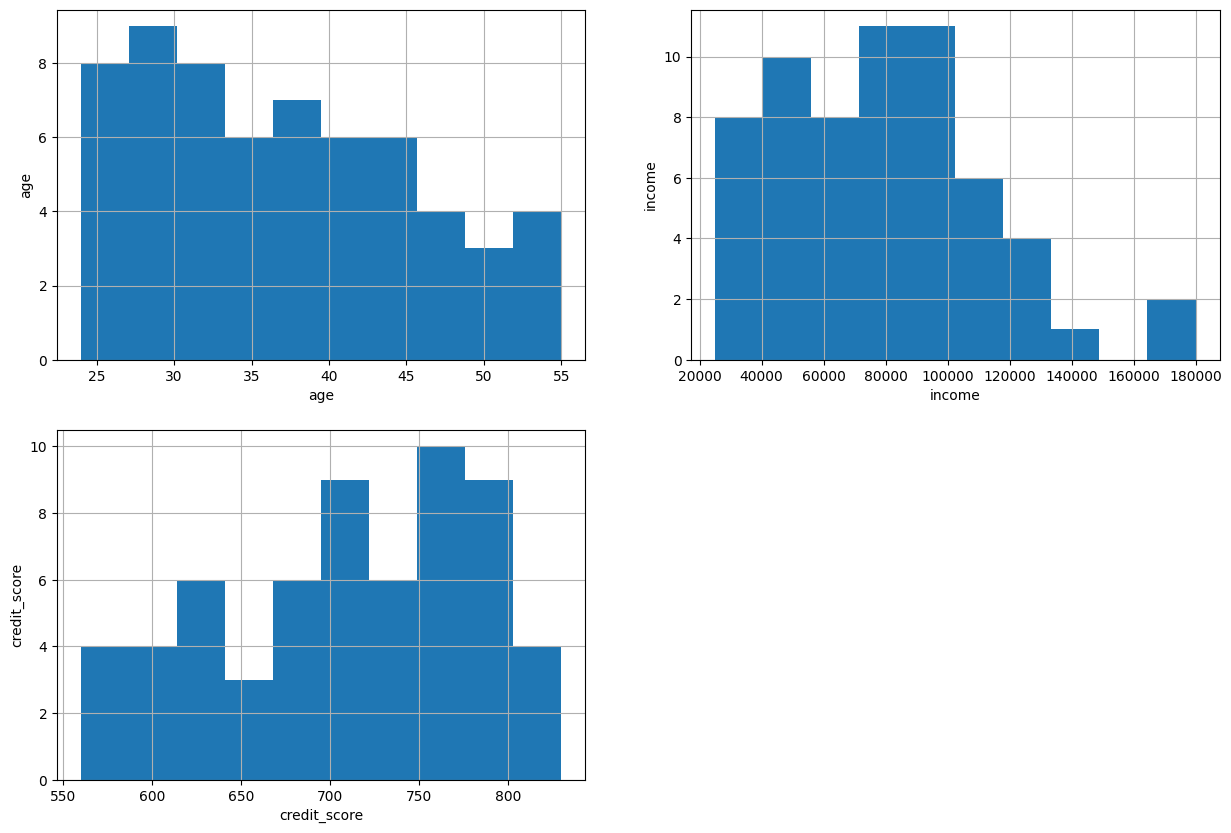

In [ ]:
# plot histogram to check distribution

plt.figure(figsize=(15,10))


plt.subplot(2, 2, 1)
fig = df.age.hist(bins=10)
fig.set_xlabel('age')
fig.set_ylabel('age')


plt.subplot(2, 2, 2)
fig = df.income.hist(bins=10)
fig.set_xlabel('income')
fig.set_ylabel('income')


plt.subplot(2, 2, 3)
fig = df.credit_score.hist(bins=10)
fig.set_xlabel('credit_score')
fig.set_ylabel('credit_score')

In [ ]:
# Find IQR

# Menghitung IQR untuk Age
IQR_age = df['Age'].quantile(0.75) - df['Age'].quantile(0.25)
Lower_fence_age = df['Age'].quantile(0.25) - (IQR_age * 3)
Upper_fence_age = df['Age'].quantile(0.75) + (IQR_age * 3)
print('Age outliers are values < {lowerboundary} or > {upperboundary}'.format(
    lowerboundary=Lower_fence_age, upperboundary=Upper_fence_age))

# Menghitung IQR untuk Annual Income
IQR_income = df['Annual_Income'].quantile(0.75) - df['Annual_Income'].quantile(0.25)
Lower_fence_income = df['Annual_Income'].quantile(0.25) - (IQR_income * 3)
Upper_fence_income = df['Annual_Income'].quantile(0.75) + (IQR_income * 3)
print('Annual Income outliers are values < {lowerboundary} or > {upperboundary}'.format(
    lowerboundary=Lower_fence_income, upperboundary=Upper_fence_income))

# Menghitung IQR untuk Spending Score
IQR_score = df['Spending Score (1-100)'].quantile(0.75) - df['Spending Score (1-100)'].quantile(0.25)
Lower_fence_score = df['Spending Score (1-100)'].quantile(0.25) - (IQR_score * 3)
Upper_fence_score = df['Spending Score (1-100)'].quantile(0.75) + (IQR_score * 3)
print('Spending Score outliers are values < {lowerboundary} or > {upperboundary}'.format(
    lowerboundary=Lower_fence_score, upperboundary=Upper_fence_score))

In [ ]:
# find outliers for Evaporation variable

IQR = df.income.quantile(0.75) - df.income.quantile(0.25)
Lower_fence = df.income.quantile(0.25) - (IQR * 3)
Upper_fence = df.income.quantile(0.75) + (IQR * 3)
print('Evaporation outliers are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))

Annual Income outliers are values < -71.75 or > 189.0


In [ ]:
# find outliers for Evaporation variable

IQR = df.credit_score.quantile(0.75) - df.credit_score.quantile(0.25)
Lower_fence = df.credit_score.quantile(0.25) - (IQR * 3)
Upper_fence = df.credit_score.quantile(0.75) + (IQR * 3)
print('Evaporation outliers are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))

Evaporation outliers are values < 290.0 or > 1130.0


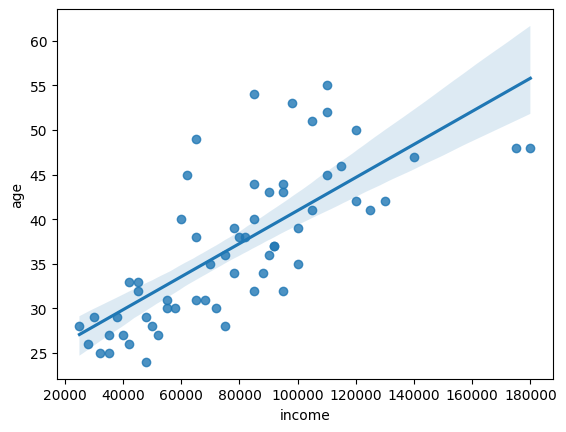

In [ ]:
sns.regplot(x="income", y="age",data=df);

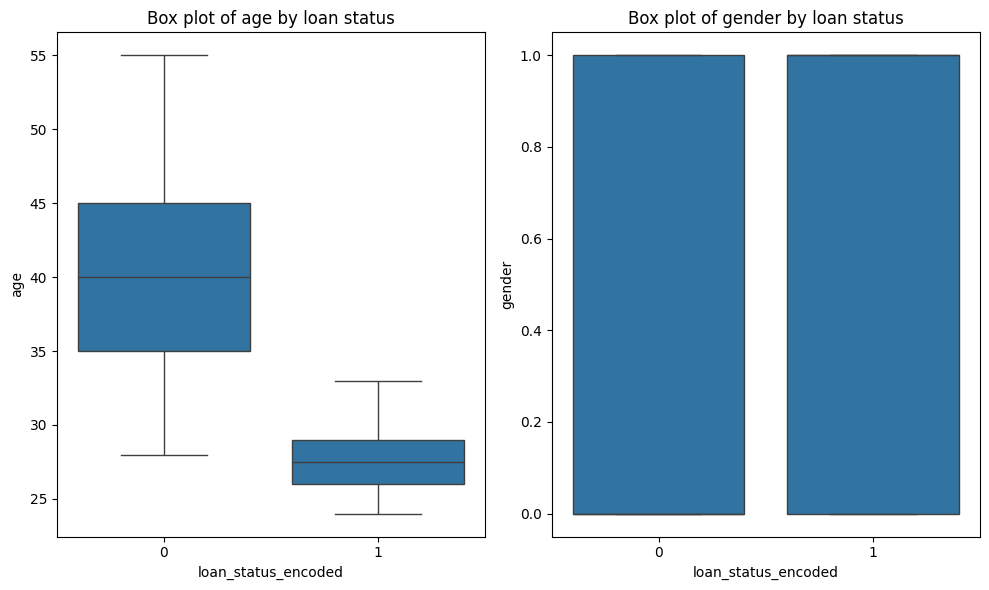

In [ ]:
plt.figure(figsize=(10, 6))
for i, col in enumerate(num_cols, 1):
    if i <= 2:  # Limit the creation of subplots to 2
        plt.subplot(1, 2, i)
        sns.boxplot(x='loan_status_encoded', y=col, data=df)
        plt.title(f"Box plot of {col} by loan status")
plt.tight_layout()
plt.show()

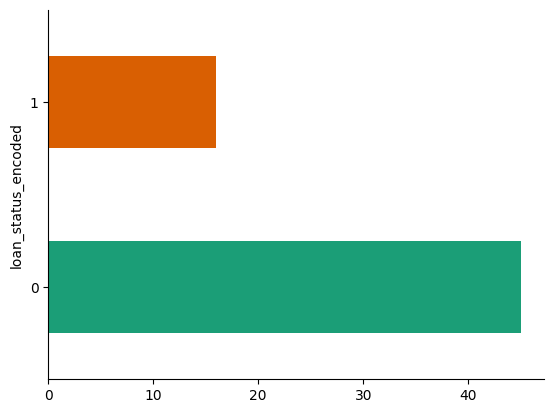

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
df.groupby('loan_status_encoded').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

## Building Model

In [15]:
X = df.drop(columns=['loan_status_encoded'])
y = df['loan_status_encoded']

KeyError: "['loan_status_encoded'] not found in axis"

In [ ]:
# Splitting Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [1]:
numerical = [col for col in X_train.columns if X_train[col].dtypes != 'O']
numerical

NameError: name 'X_train' is not defined

In [ ]:
X_train[numerical].isnull().sum()

,0
age,0
gender,0
income,0
credit_score,0
education_level_encoded,0
occupation_encoded,0
marital_status_encoded,0


In [ ]:
X_test[numerical].isnull().sum()

,0
age,0
gender,0
income,0
credit_score,0
education_level_encoded,0
occupation_encoded,0
marital_status_encoded,0


In [ ]:
# train a logistic regression model on the training set
from sklearn.linear_model import LogisticRegression


# instantiate the model
logreg = LogisticRegression(solver='liblinear', random_state=0)


# fit the model
logreg.fit(X_train, y_train)

LogisticRegression(random_state=0, solver='liblinear')

In [ ]:
# make prediction

y_pred_test = logreg.predict(X_test)

y_pred_test

array([0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1])

## Evaluate Model

In [ ]:
from sklearn.metrics import accuracy_score

print('Model accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred_test)))

Model accuracy score: 0.9231


In [ ]:
print('Training set score: {:.4f}'.format(logreg.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(logreg.score(X_test, y_test)))

Training set score: 1.0000
Test set score: 0.9231


In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_test)

print('Confusion matrix\n\n', cm)

print('\nTrue Positives(TP) = ', cm[0,0])

print('\nTrue Negatives(TN) = ', cm[1,1])

print('\nFalse Positives(FP) = ', cm[0,1])

print('\nFalse Negatives(FN) = ', cm[1,0])

Confusion matrix

 [[9 1]
 [0 3]]

True Positives(TP) =  9

True Negatives(TN) =  3

False Positives(FP) =  1

False Negatives(FN) =  0


<Axes: >

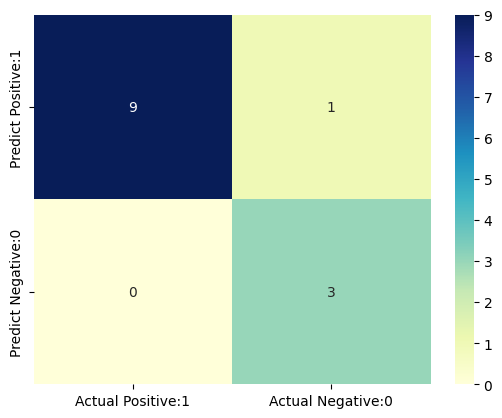

In [ ]:
cm_matrix = pd.DataFrame(data=cm, columns=['Actual Positive:1', 'Actual Negative:0'],
                                 index=['Predict Positive:1', 'Predict Negative:0'])

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.75      1.00      0.86         3

    accuracy                           0.92        13
   macro avg       0.88      0.95      0.90        13
weighted avg       0.94      0.92      0.93        13



In [ ]:
TP = cm[0,0]
TN = cm[1,1]
FP = cm[0,1]
FN = cm[1,0]

In [ ]:
classification_accuracy = (TP + TN) / float(TP + TN + FP + FN)
print('Classification accuracy : {0:0.4f}'.format(classification_accuracy))

Classification accuracy : 0.9231


In [ ]:
classification_error = (FP + FN) / float(TP + TN + FP + FN)
print('Classification error : {0:0.4f}'.format(classification_error))

Classification error : 0.0769


In [ ]:
precision = TP / float(TP + FP)
print('Precision : {0:0.4f}'.format(precision))

Precision : 0.9000


In [ ]:
recall = TP / float(TP + FN)
print('Recall or Sensitivity : {0:0.4f}'.format(recall))

Recall or Sensitivity : 1.0000
